# Checkpoint 1: preliminary chart-QA model on a subset of ChartQA

**Checkpoint 1 expectation (problem statement):** *"Preliminary model and training (on a subset of data)."*

This notebook shows where the project stands against each step of the problem statement: what is **done**, what is **partly done**, and what is **still to do**. Anything marked **TO DO** is a placeholder to fill in later. The numbers in the code cells are read live from the files in `results/`, so re-running the notebook refreshes them.

Dataset: ChartQA (HuggingFaceM4/ChartQA). Metric: ChartQA relaxed accuracy (numbers within 5% count as right, text must match exactly).

## 1. The pipeline

- **Frozen** = pretrained, never changed by us: UniChart (reads the chart), MiniLM (text to numbers), UniChart's image encoder.
- **Trained by us** = the small router and heads on top.
- The **baseline** gives the reference number the trained model has to reach.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "data_exploration" else Path.cwd()
sys.path.insert(0, str(ROOT / "utils"))
RES = ROOT / "results"


def read(name, **kw):
    path = RES / name
    return pd.read_json(path, lines=True, dtype=False, **kw) if path.exists() else None


print("project root:", ROOT)

project root: C:\Users\Likhit\ChartQA-IIITH


## 2. Step 1: subsample the data and read the charts

**What we did**
- **Validation sample (for evaluation):** 300 questions drawn from the 1,920 validation questions, half human-written and half machine-generated (`results/val_sample_300.csv`). They cover 279 charts. Everyone uses this same file so scores are comparable.
- **Training subset (for training):** 3,000 questions drawn from the 28,299 training questions, again half and half (`results/train_subset_3000.csv`). They cover 2,768 charts. None of these charts appears in the validation set.
- **Reading the charts:** instead of plain OCR we used two chart-to-table models, **UniChart** and **DePlot**. They output a table of labels and values. UniChart is the one used for training (about 6 times faster).
- Everything heavy ran on Kaggle GPUs.

In [2]:
sample = pd.read_csv(RES / "val_sample_300.csv")
subset = pd.read_csv(RES / "train_subset_3000.csv")
print(f"validation sample: {len(sample)} questions, half human-written:", int((sample.human_or_machine == 0).sum()))
print(f"training subset:   {len(subset)} questions, {subset.chart_hash.nunique()} charts, half human-written:", int((subset.human_or_machine == 0).sum()))
print()

rows = []
for name, file, table_col, time_col in [
    ("DePlot, validation sample", "deplot_val_300.jsonl", "deplot_table", "deplot_s"),
    ("UniChart, validation sample", "unichart_val_300.jsonl", "unichart_table", "unichart_s"),
    ("UniChart, training subset", "unichart_train_3000.jsonl", "unichart_table", "unichart_s"),
]:
    df = read(file)
    if df is None:
        continue
    per_chart = df.drop_duplicates("chart_hash")[time_col]
    rows.append({"run": name, "questions": len(df), "charts": df.chart_hash.nunique(),
                 "seconds per chart": round(per_chart.mean(), 2), "total minutes": round(per_chart.sum() / 60, 1),
                 "empty tables": int((df[table_col].str.strip() == "").sum()),
                 "tables with a stray <tag>": int(df[table_col].str.contains(r"<[a-z_]+>").sum())})
pd.DataFrame(rows).set_index("run")

validation sample: 300 questions, half human-written: 150
training subset:   3000 questions, 2768 charts, half human-written: 1500



,questions,charts,seconds per chart,total minutes,empty tables,tables with a stray <tag>
run,,,,,,
"DePlot, validation sample",300,279,7.27,33.8,0,0
"UniChart, validation sample",300,279,1.17,5.4,0,24
"UniChart, training subset",3000,2768,1.15,52.9,0,233


**Quality of the reading (what goes wrong in the tables)**
- Small stacked-bar segments get dropped and the row shifts left; legend text becomes fake rows; "<1" is read as 1.
- UniChart sometimes cuts a number off after the decimal point (for example `376.` for 376.1), and a few tables are garbage.
- A chart-to-table model has no colour or position information, so questions about "the green bar" cannot be answered from the table alone.

**TO DO:** compare against a plain OCR tool (for example Tesseract or EasyOCR) as an extra experiment, since the problem statement says "OCR tool".

## 3. Step 2: encode image, text and question with frozen encoders

| Input | Frozen encoder | Status |
|---|---|---|
| Question | `all-MiniLM-L6-v2` (384 numbers per question) | Done, cached |
| Table text (every cell, about 26 per table) | `all-MiniLM-L6-v2` | Done, cached |
| Chart image | UniChart's own image encoder | Done: features saved for all 2,768 training charts and 279 validation charts |

Extra hand-made features for each table cell are also given to the model (where its value ranks in its column, whether it is the largest or smallest, how well its row and column names match the question).

**Image result so far:** feeding the image into the model has **not helped**. A single averaged image vector hurt (45% vs 49%). A 4x4 grid of 16 regional vectors, with the question attending over the regions, is neutral overall and maybe slightly helpful on colour and position questions (see section 7).

**TO DO:** try a finer 8x8 map (the code is ready: `--image-grid 8`; it needs a short Kaggle run to produce the features).

In [3]:
from extract_image_features import load_features

for label, folder in [("training charts", "image_features"), ("validation charts", "image_features_val"), ("8x8 training charts", "image_features_8x8")]:
    path = RES / folder
    if path.exists() and any(path.glob("features_part_*.npz")):
        hashes, feats = load_features(path)
        print(f"{label:<22} {len(hashes)} charts, features per chart {feats.shape[1:]} (whole-chart vector + grid regions x 1024 numbers)")
    else:
        print(f"{label:<22} not found (git-ignored; regenerate with utils/extract_image_features.py)")

training charts        2768 charts, features per chart (17, 1024) (whole-chart vector + grid regions x 1024 numbers)
validation charts      279 charts, features per chart (17, 1024) (whole-chart vector + grid regions x 1024 numbers)
8x8 training charts    not found (git-ignored; regenerate with utils/extract_image_features.py)


## 4. Step 3: scope the answer space

**Choice: extractive.** The model picks the answer out of the table (a cell, a number or a name), with two helpers: a **compute** head for answers that need a calculation, and a **yes/no** head. It does **not** classify into numeric bins or a fixed list of answers.

**Why (from the data; full analysis in `answer_space.ipynb`)**
- **Numbers are too spread out to bin.** Among 22,847 numeric training answers there are 9,675 distinct values, and about 250 bins of 10% width are in use. A bin classifier can only choose the right bin if it has already read the number from the chart, so reading it is the real task.
- **Names are a long tail.** 2,604 distinct text answers; the 1,000 most common cover only 66%. A fixed list would miss a third.
- **Most answers are in the table.** On the validation sample, 95% of text answers and about 90% of look-up answers appear in the extracted table (75% of all answers with DePlot's tables, 72% with UniChart's).
- **But not all.** Questions that need a calculation have their answer in the table only 38% of the time, so extraction alone is not enough. 36% of human-written questions are of that kind.

**TO DO:** write this justification into the report.

## 5. Step 4: the model and how it is trained

**Parts**

| Part | What it decides | Learns from |
|---|---|---|
| **Router** | Which kind of answer the question needs: extract, compute, yes/no or count rows | The "kind" label of each training question |
| **Extract head** | Which table cell is the answer (scores every cell) | Which cell(s) hold the true answer |
| **Compute head** | Which operation (sum, difference, average, ratio, count above or below a value) and which cells; code does the arithmetic | The operation and cells of each verified recipe |
| **Yes/no head** | Yes or no | The yes/no answers |
| Count rows | Answer = number of table rows (a rule, not trained) | n/a |

**Training labels** (the dataset only gives final answers, so we worked out where each answer comes from):
1. A rule-based label-maker finds the cell that holds the answer, or marks yes/no and row-count answers.
2. For questions the rules cannot label, DeepSeek proposes a calculation recipe **without seeing the answer**. We keep it only if running the recipe reproduces the true answer. This recovered 181 of 675 unlabelled training questions and exposed 23 false rule-based compute labels.
3. A bug in the first label-maker (it matched 2014 to cells reading 2013 and 2015) was found and fixed; all labels were rebuilt.

The frozen encoders are not trained; only the small router and heads are.

In [4]:
final = read("unichart_train_3000_final_labels.jsonl")
if final is not None:
    order = ["extract", "compute", "yes_no", "count_rows", "unusable"]
    table = pd.crosstab(final["kind"], final["human_or_machine"]).reindex(order)
    table.columns = ["human-written", "machine-generated"]
    table["all"] = table.sum(axis=1)
    table["% of 3,000"] = (table["all"] / len(final) * 100).round(1)
    print(f"usable training labels: {int((final.kind != 'unusable').sum())} of {len(final)} ({(final.kind != 'unusable').mean() * 100:.1f}%)")
    display(table)

usable training labels: 2483 of 3000 (82.8%)


,human-written,machine-generated,all,"% of 3,000"
kind,,,,
extract,665,1349,2014,67.1
compute,293,3,296,9.9
yes_no,149,0,149,5.0
count_rows,23,1,24,0.8
unusable,370,147,517,17.2


Questions marked **unusable** (about 17%) have no table-based label: they need the image (colour or position), the table is wrong or missing, the question or label is questionable, or the calculation was not recovered. They are left out of training for now.

## 6. Step 5: evaluation with relaxed accuracy, and comparison with the baseline

All systems are scored on the **same 300 held-out validation questions** with the same metric. The test set has not been used.

- **Baselines (no training):** a chart reader writes a table, then DeepSeek (`deepseek-chat`, temperature 0) answers from the table and the question.
- **Trained model:** the router and heads described above, trained on the 3,000-question subset. Each row is the average of 3 training runs with different random seeds (the spread between seeds is about 5 points, so differences of 1 to 3 points are not meaningful).

,overall,human-written,machine-generated
Baseline: DePlot + DeepSeek,81.0,74.0,88.0
Baseline: UniChart + DeepSeek (raw table),74.0,62.0,86.0
Baseline: UniChart + DeepSeek (rows split),77.0,65.3,88.7
Model v1: text only (no compute head),48.9,33.3,64.4
Model v1 + averaged image vector,45.3,25.8,64.9
Model v2: text + compute head,52.0,39.3,64.7
Model v2 + image grid 4x4,51.6,40.9,62.2


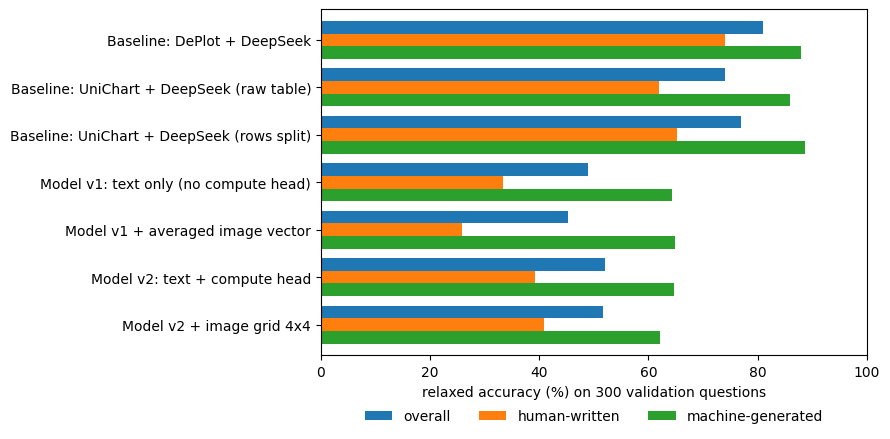

In [5]:
def baseline(file):
    df = read(file)
    if df is None:
        return None
    return {"overall": df.correct.mean() * 100, "human-written": df[df.human_or_machine == 0].correct.mean() * 100,
            "machine-generated": df[df.human_or_machine == 1].correct.mean() * 100}


def model_runs(files):
    runs = [json.load(open(RES / f)) for f in files if (RES / f).exists()]
    if not runs:
        return None
    pick = lambda key: [r["router"][key] * 100 for r in runs]
    return {"overall": np.mean(pick("overall")), "human-written": np.mean(pick("human-written")),
            "machine-generated": np.mean(pick("machine")), "runs": len(runs), "spread": (min(pick("overall")), max(pick("overall")))}


systems = {
    "Baseline: DePlot + DeepSeek": baseline("deplot_val_300_answers.jsonl"),
    "Baseline: UniChart + DeepSeek (raw table)": baseline("unichart_val_300_answers.jsonl"),
    "Baseline: UniChart + DeepSeek (rows split)": baseline("unichart_val_300_answers_clean.jsonl"),
    "Model v1: text only (no compute head)": model_runs(["model_v1_text.json", "model_v1_text_seed1.json", "model_v1_text_seed2.json"]),
    "Model v1 + averaged image vector": model_runs(["model_v1_image.json", "model_v1_image_seed1.json", "model_v1_image_seed2.json"]),
    "Model v2: text + compute head": model_runs(["model_v2_text_s0.json", "model_v2_text_s1.json", "model_v2_text_s2.json"]),
    "Model v2 + image grid 4x4": model_runs(["model_v2_grid_s0.json", "model_v2_grid_s1.json", "model_v2_grid_s2.json"]),
}
summary = pd.DataFrame({k: v for k, v in systems.items() if v}).T
summary = summary[["overall", "human-written", "machine-generated"]].astype(float).round(1)
display(summary)

ax = summary.plot.barh(figsize=(9, 4.5), width=0.8)
ax.invert_yaxis()
ax.set_xlabel("relaxed accuracy (%) on 300 validation questions")
ax.set_xlim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

**Reading the table**
- The baseline reaches **77 to 81%**. DePlot tables give a higher score than UniChart tables, mostly on human-written questions.
- Our best trained model reaches about **52%**. The gap is mainly on **human-written questions** (about 39% vs 65 to 74%), which need calculations, colour or position reasoning, and messy tables.
- Adding the **compute head** raised the model from about 49% to 52% (human-written questions: 33% to 39%).
- On **machine-generated** questions the model is closer: about 65% vs 86 to 89%.
- The pooled image vector made the model worse; the 4x4 image grid is neutral overall.

**Caveats:** 300 validation questions (group scores can move by 6 to 7 points); training on only 3,000 questions; the router sends about 7% of questions to the wrong head.

**TO DO:** evaluate on the **test set once**, at the end, with the final model.

## 7. Step 6: error analysis, OCR-extraction failures vs reasoning failures

**Mapping used**
- **OCR / extraction failure:** the table is wrong or missing data (UniChart drops digits or rows, invents rows, loses a column).
- **Reasoning failure:** the table is fine but the model picked the wrong cell, operation or answer.
- **Out of scope for the table-based model:** the question needs the image (colour or position), or the label or question is questionable.

### 7a. Baseline (all wrong answers sorted by hand, mostly from the table text)

In [6]:
dp = pd.read_csv(RES / "wrong_answers_sorted.csv") if (RES / "wrong_answers_sorted.csv").exists() else None
uc = pd.read_csv(RES / "unichart_wrong_answers_sorted.csv") if (RES / "unichart_wrong_answers_sorted.csv").exists() else None
if dp is not None and uc is not None:
    cmp = pd.DataFrame({"DePlot + DeepSeek": dp.groupby("cause").size(), "UniChart + DeepSeek": uc.groupby("cause").size()}).fillna(0).astype(int)
    cmp.loc["TOTAL wrong"] = cmp.sum()
    display(cmp)
    print("Reading failures = 'table wrong or missing data'; reasoning failures = 'LLM reasoning/arithmetic error, table looks fine'.")

,DePlot + DeepSeek,UniChart + DeepSeek
cause,,
"LLM reasoning/arithmetic error, table looks fine",11,8
label or question is questionable,14,14
"right answer, strict scoring (format)",9,9
table wrong or missing data,11,23
"visual question (colour/position), table can't answer",12,15
TOTAL wrong,57,69


Reading failures = 'table wrong or missing data'; reasoning failures = 'LLM reasoning/arithmetic error, table looks fine'.


### 7b. Trained model, first pass
From each wrong answer's route through the model (v2, text only, 3 seeds): was the question out of reach of the table, was it sent to the wrong head, or did the right head pick the wrong answer?

This is a quick automatic split, not yet a hand-checked one. **TO DO:** go through the trained model's mistakes by hand, as was done for the baseline, and add the chart images for the written report.

In [7]:
def classify(df):
    wrong = df[~df.correct]
    out_of_reach = wrong.true_kind == "unusable"
    misrouted = (~out_of_reach) & (wrong.true_kind != wrong.routed_kind)
    right_head = (~out_of_reach) & (~misrouted)
    return pd.Series({"wrong in total": len(wrong),
                      "no table-based label (needs the image, bad table or questionable label)": int(out_of_reach.sum()),
                      "router sent it to the wrong head": int(misrouted.sum()),
                      "right head, wrong cell or calculation": int(right_head.sum())})


runs = [read(f"model_v2_text_s{s}.answers.jsonl") for s in (0, 1, 2)]
runs = [r for r in runs if r is not None]
if runs:
    table = pd.concat([classify(r) for r in runs], axis=1)
    table.columns = [f"seed {i}" for i in range(len(runs))]
    table["average"] = table.mean(axis=1).round(1)
    display(table)
    print("Out of 300 validation questions. 'Right head, wrong cell or calculation' is the reasoning failure to attack next.")
    print("To tell extraction failures from the rest inside the first row, see the hand-sorted baseline in 7a.")

,seed 0,seed 1,seed 2,average
wrong in total,143,137,152,144.0
"no table-based label (needs the image, bad table or questionable label)",36,38,37,37.0
router sent it to the wrong head,17,19,18,18.0
"right head, wrong cell or calculation",90,80,97,89.0


Out of 300 validation questions. 'Right head, wrong cell or calculation' is the reasoning failure to attack next.
To tell extraction failures from the rest inside the first row, see the hand-sorted baseline in 7a.


## 8. 10 annotated example predictions (TO DO)

The final deliverable asks for 10 annotated predictions. Below, 10 validation questions are pre-selected (a mix of right and wrong answers across answer kinds) from the v2 text-only model. **TO DO:** for each one, look at the chart, then fill in the annotation: what the model did and why, and whether a wrong answer is an OCR failure or a reasoning failure.

In [8]:
ans = read("model_v2_text_s0.answers.jsonl")
if ans is not None:
    rng = np.random.default_rng(0)
    picks = []
    for kind, n_right, n_wrong in [("extract", 2, 2), ("compute", 1, 2), ("yes_no", 1, 0), ("unusable", 0, 2)]:
        pool = ans[ans.true_kind == kind]
        for flag, n in ((True, n_right), (False, n_wrong)):
            part = pool[pool.correct == flag]
            if n and len(part):
                picks.append(part.sample(min(n, len(part)), random_state=int(rng.integers(1000))))
    examples = pd.concat(picks).head(10).reset_index(drop=True)
    examples["annotation (TO DO)"] = ""
    display(examples[["row_idx", "query", "label", "answer", "correct", "true_kind", "routed_kind", "annotation (TO DO)"]])

,row_idx,query,label,answer,correct,true_kind,routed_kind,annotation (TO DO)
0,86,What is Female-to-male ratio to time devoted t...,3.37,3.37,True,extract,extract,
1,174,What does Orange line represents?,Urban,Urban,True,extract,extract,
2,1620,What percentage of Nigerians use Facebook and ...,86.2,81.6%,False,extract,extract,
3,1323,How many Democratic senators make up the 116th...,45,53,False,extract,extract,
4,545,What is the difference between Carex and Palmo...,24.3,24.3,True,compute,compute,
5,137,What is the difference in % between Poland and...,17.05,32.26%,False,compute,extract,
6,1195,"As of March 2020, how many enterprises had a t...",15,0,False,compute,extract,
7,254,Is the crude oil import price greater than 25$...,Yes,yes,True,yes_no,yes_no,
8,60,Which state shows the highest fertility rate?,Malawi,Malawi -,False,unusable,extract,
9,923,How many opinions have a percentage of equal o...,3,1,False,unusable,compute,


Template for each annotation (copy into the report):

| # | Chart (image) | Question | True answer | Model answer | What the model did | Why right / wrong | OCR failure or reasoning failure? |
|---|---|---|---|---|---|---|---|
| 1 | TO DO | | | | | | |
| 2 | TO DO | | | | | | |
| ... | | | | | | | |
| 10 | TO DO | | | | | | |

## 9. What is not done yet (to fill in later)

| Item | Why it matters | Status |
|---|---|---|
| Hand-checked error analysis of the **trained** model | Step 6 of the problem statement | TO DO (first pass above) |
| 10 annotated example predictions | Final deliverable | TO DO |
| Written justification of the answer space | Step 3: "justify the choice in the report" | TO DO |
| Report: chart QA vs natural-image VQA | Final deliverable | TO DO |
| Finer image map (8x8) | Tests whether the image can help, especially on colour and position questions | Code ready; needs a Kaggle feature run |
| More training data (all 18,271 charts, about 6 hours of UniChart on Kaggle) | The model is trained on only 10% of the training questions | TO DO |
| Better extract head (about 61% on extract-type questions) and router (about 93%) | The biggest remaining gaps | TO DO |
| Compare with a plain OCR tool | The problem statement says "OCR tool" | TO DO (optional) |
| Questions that need the image (about 4.5% of the training subset) | Colour and position questions have no table-based label | Parked |
| Evaluate once on the **test set** | Final, honest number | TO DO (at the end) |
| Ask the mentor: encoders used in project 13, the expectation for Checkpoint 1, the date of the next session | Make sure we match expectations | TO DO |
| Deployment and demo | Checkpoints 3 and 4 | Later |

## 10. How to reproduce (in order)

```bash
python utils/make_val_sample.py          # shared validation sample (already saved: do not re-run, everyone loads the CSV)
python utils/make_train_subset.py        # 3,000-question training subset
python utils/make_subset_images.py       # pack its images for Kaggle
python utils/run_unichart.py --sample-csv results/train_subset_3000.csv --chart-images <packed file>   # on Kaggle
python utils/answer_and_score.py         # baseline: DeepSeek answers from the tables (needs DEEPSEEK_API_KEY in .env)
python utils/build_labels.py --tables results/unichart_train_3000.jsonl --out results/unichart_train_3000_labels.jsonl
python utils/propose_recipes.py --tables results/unichart_train_3000.jsonl --labels results/unichart_train_3000_labels.jsonl --out results/unichart_train_3000_recipes.jsonl
python utils/merge_labels.py             # final training labels
python utils/extract_image_features.py   # on Kaggle: UniChart image features
python utils/embed_examples.py           # frozen MiniLM embeddings (cached in datasets/embeddings/)
python utils/train_model.py --epochs 20 --seed 0                      # text only
python utils/train_model.py --epochs 20 --seed 0 --image-mode grid    # with the image grid
```

Notes: on Windows, `torch` must be imported before numpy and pandas (the scripts do this). The decisions and reasons behind each step are in `PROJECT_LOG.md`.